# EDA — DVF

**Projet :** Compagnon Immobilier ·


# Chargement des librairies et fonctions de tests

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

def eta2_kruskal(groupes):
    """Kruskal-Wallis + taille d'effet eta² (part de la variabilité des rangs expliquée par les groupes)."""
    H, p = stats.kruskal(*groupes)
    k, n = len(groupes), sum(len(g) for g in groupes)
    return H, p, (H - k + 1) / (n - k)

def r_mannwhitney(a, b):
    """Mann-Whitney + taille d'effet r rang-bisérial (de -1 à 1).
    r > 0 : les valeurs de a ont tendance à être plus élevées que celles de b.
    (1 + r) / 2 = probabilité qu'une valeur tirée dans a dépasse une valeur tirée dans b."""
    U, p = stats.mannwhitneyu(a, b)
    return U, p, 2 * U / (len(a) * len(b)) - 1


# 0. Cadre de l'analyse


**Objectif :** construire la variable cible du projet à partir de DVF+, la décrire, puis étudier ce qui la fait varier.

| Élément | Choix |
|---|---|
| Source | DVF+ (Cerema), table mutation. Voir la fiche de description. |
| Périmètre | Ventes d'un seul logement ancien (une maison ou un appartement), dans une seule commune, en France métropolitaine. VEFA et DOM exclus. L'Alsace-Moselle n'est pas couverte par DVF+. |
| Période étudiée | 2014-2023. L'année 2025 est réservée au test et n'est pas regardée. L'année 2024 est mise de côté en attendant la décision du groupe. |
| Cible | Prix médian au m² par commune et par année, accompagné du nombre de ventes. |
| Données utilisées | La population complète (8 181 968 ventes) pour construire la cible. L'échantillon d'apprentissage (835 288 ventes) pour étudier les relations entre variables. |
| Points provisoires | La période définitive et le seuil de maille seront confirmés par le groupe le 14/10. |

**Plan**
- **A. La cible :** construction de la cible (A1) et nombre de communes couvertes selon le nombre minimum de ventes retenu (A2).
- **B. Relations avec la cible :** ce qui fait varier le prix au m² : surface (B1), type de bien (B2), département (B3), évolution dans le temps (B4), nombre de pièces (B5), terrain (B6) et dépendances (B7).
- **C. Liens avec les autres sources :** à compléter quand les autres bases du projet seront prêtes (par exemple les taux d'intérêt).

# A. La cible

*Responsable :* CN

**Chargements de la population**

In [3]:
# Dossier des 93 fichiers Parquet de la population filtrée
dossier_pop = Path("/home/naude/formation/projet_compagnon/data/dvf_plus_residentiel")

cols = ["idmutation", "coddep", "l_codinsee", "anneemut", "datemut",
        "libtypbien", "valeurfonc", "sbati"]

# Lecture fichier par fichier, en ne gardant que les années hors test
pop = pd.concat(
    [pd.read_parquet(p, columns=cols) for p in sorted(dossier_pop.glob("*.parquet"))],
    ignore_index=True,
)
pop = pop[pop["anneemut"] <= 2023]

print(pop.shape)
print(round(pop.memory_usage(deep=True).sum() / 1e9, 2), "Go en mémoire")
pop.head()


(8181968, 8)
0.83 Go en mémoire


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati
0,16,01,01378,2014,2014-05-20,UNE MAISON,222300.0,88.0
1,476,01,01160,2014,2014-02-28,UNE MAISON,1084000.0,212.0
2,8975,01,01022,2014,2014-09-29,UNE MAISON,139000.0,90.0
3,9113,01,01210,2014,2014-12-11,UN APPARTEMENT,75700.0,41.0
4,9498,01,01185,2014,2014-04-11,UNE MAISON,58000.0,39.0


### A1. Construction de la cible

**Variables :** `valeurfonc` (prix de vente, en €), `sbati` (surface bâtie, en m²), `libtypbien` (maison ou appartement), `l_codinsee` (code de la commune), `anneemut` (année de la vente).

**Pourquoi regarder cela :** la cible est un prix médian au m² par commune et par année. Avant de la calculer, il faut vérifier que le prix au m² de chaque vente est plausible. Une valeur foncière nulle ou une surface erronée peut fausser la médiane, surtout dans les petites communes où il y a peu de ventes.

**Méthode :**
1. calculer le prix au m² de chaque vente ;
2. repérer les valeurs manquantes, nulles et extrêmes, par type de bien ;
3. examiner quelques cas extrêmes pour fixer des règles d'exclusion ;
4. calculer la table commune × année : prix médian au m² et nombre de ventes.

#### 1. Calcul du prix au m² de chaque vente

In [4]:
# Variables construites
pop["prix_m2"] = pop["valeurfonc"] / pop["sbati"]
pop["type_bien"] = pop["libtypbien"].map({"UNE MAISON": "maison",
                                          "UN APPARTEMENT": "appartement"})

# Distribution du prix au m² par type, avec les centiles extrêmes
pop.groupby("type_bien")["prix_m2"].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
).round(0)

,count,mean,std,min,1%,5%,50%,95%,99%,max
type_bien,,,,,,,,,,
appartement,3490738.0,3707.0,12246.0,0.0,441.0,948.0,2910.0,9639.0,13336.0,19545455.0
maison,4688611.0,2286.0,17652.0,0.0,213.0,543.0,1888.0,5034.0,8409.0,25781250.0


**Constat :**
- Le prix médian au m² est de 2 910 € pour les appartements et de 1 888 € pour les maisons.
- La distribution est très asymétrique : la moyenne dépasse nettement la médiane, et les maximums sont impossibles (19,5 millions d'euros au m² pour un appartement, 25,8 millions pour une maison).
- Entre le 1er et le 99e centile, le prix au m² va de 441 à 13 336 € pour les appartements, et de 213 à 8 409 € pour les maisons.



#### 2. Valeurs manquantes, nulles ou extrêmes

In [5]:
# Cas qui empêchent de calculer un prix au m² correct
print("valeurfonc manquante :", pop["valeurfonc"].isna().sum())
print("valeurfonc = 0       :", (pop["valeurfonc"] == 0).sum())
print("sbati = 0            :", (pop["sbati"] == 0).sum())

# Indicatrice : True si la valeur foncière est à 0
pop["vf_nulle"] = pop["valeurfonc"] == 0

# Nombre de ventes à 0 € par année
pop.groupby("anneemut")["vf_nulle"].sum()

valeurfonc manquante : 2619
valeurfonc = 0       : 550
sbati = 0            : 0


anneemut
2014    299
2015    234
2016     17
2017      0
2018      0
2019      0
2020      0
2021      0
2022      0
2023      0
Name: vf_nulle, dtype: int64

In [6]:
# Valeurs foncières manquantes par année (même idée que pour les valeurs à 0)
print(pop["valeurfonc"].isna().groupby(pop["anneemut"]).sum())

# Prix au m² très bas (hors valeurs à 0) et très hauts
bas = pop[(pop["prix_m2"] > 0) & (pop["prix_m2"] < 100)]
haut = pop[pop["prix_m2"] > 20000]

print("\nPrix au m² entre 0 et 100 € :", len(bas))
print(bas["type_bien"].value_counts())
print("\nPrix au m² au-dessus de 20 000 € :", len(haut))
print(haut["type_bien"].value_counts())
print(haut["coddep"].value_counts().head(5))

display(bas.sample(8, random_state=42))
display(haut.sample(8, random_state=42))

anneemut
2014      4
2015     45
2016    298
2017    299
2018    217
2019    349
2020    367
2021    399
2022    333
2023    308
Name: valeurfonc, dtype: int64

Prix au m² entre 0 et 100 € : 28786
type_bien
maison         17348
appartement    11438
Name: count, dtype: int64

Prix au m² au-dessus de 20 000 € : 7743
type_bien
appartement    4229
maison         3514
Name: count, dtype: int64
coddep
75    3453
06     892
83     702
92     432
33     398
Name: count, dtype: int64


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati,prix_m2,type_bien,vf_nulle
7875528,8785559,79,79074,2021,2021-11-17,UNE MAISON,3000.0,76.0,39.473684,maison,False
1068521,13315983,13,13059,2023,2023-07-18,UNE MAISON,1.0,105.0,0.009524,maison,False
3141673,9806268,34,34183,2021,2021-06-30,UNE MAISON,8500.0,165.0,51.515152,maison,False
4283290,65388,45,45232,2014,2014-02-27,UNE MAISON,1014.0,101.0,10.039604,maison,False
2092897,1720007,28,28168,2015,2015-07-02,UN APPARTEMENT,1.0,59.0,0.016949,appartement,False
5616028,11646590,61,61098,2022,2022-12-29,UNE MAISON,5000.0,55.0,90.909091,maison,False
4539956,9620862,49,49180,2021,2021-11-29,UNE MAISON,7060.0,96.0,73.541667,maison,False
6913164,615108,75,75111,2014,2014-03-24,UN APPARTEMENT,1000.0,35.0,28.571429,appartement,False


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati,prix_m2,type_bien,vf_nulle
7147493,11487421,75,75108,2022,2022-04-01,UN APPARTEMENT,1095000.0,48.0,22812.500000,appartement,False
483332,12430807,06,06104,2023,2023-09-06,UNE MAISON,5400000.0,160.0,33750.000000,maison,False
2905981,10481471,33,33236,2022,2022-12-20,UNE MAISON,2400000.0,87.0,27586.206897,maison,False
7075743,7653921,75,75101,2020,2020-02-04,UN APPARTEMENT,5900000.0,152.0,38815.789474,appartement,False
8141457,4883955,83,83119,2017,2017-12-21,UNE MAISON,2350000.0,61.0,38524.590164,maison,False
7082141,7999303,75,75118,2020,2020-07-17,UN APPARTEMENT,380000.0,16.0,23750.000000,appartement,False
7128147,10575234,75,75107,2022,2022-12-15,UN APPARTEMENT,5400000.0,220.0,24545.454545,appartement,False
384290,6607514,06,06029,2019,2019-09-25,UNE MAISON,10500000.0,378.0,27777.777778,maison,False


**Résultat :** Les 550 ventes à 0 € se concentrent entre 2014 et 2016 (299 en 2014, 234 en 2015, 17 en 2016), et il n'y en a aucune à partir de 2017. 

**Interprétation :** Ce ne sont donc pas des ventes symboliques, qu'on retrouverait chaque année, mais probablement un défaut d'enregistrement des premières années de la base. La documentation du Cerema ne l'explique pas : c'est une hypothèse.

**Impact projet :** Ces ventes seront exclues. Elles ne représentent pas un prix de marché, et elur nombre trop faible pour pseser sur les résultats.


In [7]:
# Valeurs foncières manquantes par année
print(pop["valeurfonc"].isna().groupby(pop["anneemut"]).sum())

# Nombre de ventes touchées selon plusieurs seuils possibles
for s in [10, 50, 100]:
    print(f"prix au m² < {s} € :", ((pop["prix_m2"] > 0) & (pop["prix_m2"] < s)).sum())
for s in [20000, 30000, 50000]:
    print(f"prix au m² > {s} € :", (pop["prix_m2"] > s).sum())

# Exemples aux deux bouts
tres_bas = pop[(pop["prix_m2"] > 0) & (pop["prix_m2"] < 50)]
tres_haut = pop[pop["prix_m2"] > 30000]
print(tres_haut["coddep"].value_counts().head(5))

display(tres_bas.sample(8, random_state=42))
display(tres_haut.sample(8, random_state=42))

anneemut
2014      4
2015     45
2016    298
2017    299
2018    217
2019    349
2020    367
2021    399
2022    333
2023    308
Name: valeurfonc, dtype: int64
prix au m² < 10 € : 7955
prix au m² < 50 € : 17607
prix au m² < 100 € : 28786
prix au m² > 20000 € : 7743
prix au m² > 30000 € : 2021
prix au m² > 50000 € : 540
coddep
75    542
06    261
83    260
33    147
92     90
Name: count, dtype: int64


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati,prix_m2,type_bien,vf_nulle
7087417,8308910,75,75109,2020,2020-12-23,UN APPARTEMENT,1.0,107.0,0.009346,appartement,False
8681989,5896021,88,88195,2018,2018-10-30,UNE MAISON,800.0,50.0,16.000000,maison,False
4468584,8718821,48,48193,2021,2021-08-30,UNE MAISON,3052.0,65.0,46.953846,maison,False
188849,10392219,03,03206,2022,2022-06-01,UNE MAISON,3000.0,72.0,41.666667,maison,False
8610952,1227909,87,87085,2015,2015-10-05,UNE MAISON,16.0,103.0,0.155340,maison,False
559533,885339,07,07147,2014,2014-06-25,UNE MAISON,1.0,90.0,0.011111,maison,False
7091352,8529215,75,75104,2020,2020-09-22,UN APPARTEMENT,250.0,18.0,13.888889,appartement,False
318292,2642420,06,06088,2016,2016-11-21,UN APPARTEMENT,3330.0,102.0,32.647059,appartement,False


,idmutation,coddep,l_codinsee,anneemut,datemut,libtypbien,valeurfonc,sbati,prix_m2,type_bien,vf_nulle
4223905,12575362,44,44184,2023,2023-12-11,UNE MAISON,2707400.0,80.0,3.384250e+04,maison,False
7166818,12388450,75,75108,2023,2023-04-11,UN APPARTEMENT,4940000.0,148.0,3.337838e+04,appartement,False
5374412,11845710,59,59378,2022,2022-10-28,UNE MAISON,722590020.0,119.0,6.072185e+06,maison,False
2942804,12787486,33,33529,2023,2023-12-18,UNE MAISON,9350000.0,198.0,4.722222e+04,maison,False
2935227,12287634,33,33236,2023,2023-07-28,UNE MAISON,2000000.0,54.0,3.703704e+04,maison,False
7132564,10800160,75,75106,2022,2022-05-04,UN APPARTEMENT,465000.0,10.0,4.650000e+04,appartement,False
408799,8057990,06,06029,2020,2020-07-02,UN APPARTEMENT,3187537.0,99.0,3.219734e+04,appartement,False
7184823,13263365,75,75107,2023,2023-09-06,UN APPARTEMENT,4200000.0,139.0,3.021583e+04,appartement,False


**Résultat :**
- Les valeurs foncières à 0 € (550) se trouvent entre 2014 et 2016, et les valeurs manquantes (2 619) à partir de 2016. Le total des deux reste stable, autour de 300 par an : il s'agit probablement d'un changement de codage, une valeur absente étant notée 0 jusqu'en 2015, puis laissée vide. Les deux cas sont traités ensemble comme « valeur foncière absente ».
- Sous 50 € au m² (17 607 ventes), les exemples examinés ne correspondent pas à des prix de marché : valeurs de 1 € à quelques centaines d'euros pour un logement entier. Certains cas peuvent être des viagers (seul le bouquet est déclaré) ou des ventes de parts, que DVF+ ne permet pas de repérer.
- Au-dessus de 50 000 € au m² (540 ventes), on trouve des erreurs manifestes, par exemple 722 millions d'euros pour une maison de 119 m². Entre 30 000 et 50 000 €, les ventes examinées sont en majorité plausibles : Paris (7e, 8e), Lège-Cap-Ferret.

**Avis métier :** la fiche de la DGFiP sur les méthodes d'évaluation rappelle que tous les prix déclarés ne reflètent pas le marché : ventes entre proches, adjudications. Elle conseille aussi, quand le marché est peu actif, d'élargir la zone géographique ou la période d'observation. Les fourchettes retenues ont été comparées avec l'application DVF d'Etalab (explore.data.gouv.fr) : prix médian de 179 € au m² à Ninville (52), plus de 26 000 € au m² dans une section de Megève (74). Cette application s'appuie sur DVF et non sur DVF+, et ne couvre pas exactement la même période : elle donne un ordre de grandeur, pas une référence exacte.

**Interprétation :** des prix au m² très bas ou très élevés peuvent être réels. Une recherche complémentaire le confirme : médiane de 179 € au m² à Ninville (52), et plus de 26 000 € au m² dans une section de Megève. Les seuils sont donc choisis larges, pour ne retirer que les valeurs impossibles.

**Action :** trois règles d'exclusion, appliquées avant le calcul de la cible : valeur foncière absente, prix au m² inférieur à 50 €, prix au m² supérieur à 50 000 €.

**Biais / limites :** les seuils restent un choix. Les ventes entre proches et les viagers, dont le prix déclaré n'est pas un prix de marché, ne peuvent pas être repérés. Pour une maison, le prix au m² rapporte aussi la valeur du terrain à la seule surface bâtie.

#### Règles et Table cible

In [8]:
def regles_exclusion(d, afficher=False):
    """Applique les règles de A1 et ajoute le prix au m² et le type de bien.
    Garde les ventes avec une valeur foncière et un prix au m² entre 50 et 50 000 €."""
    prix_m2 = d["valeurfonc"] / d["sbati"]
    r1 = d["valeurfonc"].notna() & (d["valeurfonc"] > 0)   # valeur foncière présente
    r2 = prix_m2 >= 50                                      # seuil bas
    r3 = prix_m2 <= 50000                                   # seuil haut

    if afficher:
        print("Ventes au départ           :", len(d))
        print("Valeur foncière présente   :", r1.sum())
        print("Prix au m² >= 50 €         :", (r1 & r2).sum())
        print("Prix au m² <= 50 000 €     :", (r1 & r2 & r3).sum())

    garde = r1 & r2 & r3
    sortie = d[garde].copy()
    sortie["prix_m2"] = prix_m2[garde]
    sortie["type_bien"] = sortie["libtypbien"].map({"UNE MAISON": "maison",
                                                    "UN APPARTEMENT": "appartement"})
    return sortie


# Application à la population, avec affichage de l'entonnoir
ventes = regles_exclusion(pop, afficher=True)
ventes["est_maison"] = ventes["type_bien"] == "maison"

# Table cible : une ligne par commune et par année
cible = (ventes.groupby(["l_codinsee", "anneemut"])
               .agg(coddep=("coddep", "first"),
                    nb_ventes=("prix_m2", "size"),
                    prix_m2_median=("prix_m2", "median"),
                    part_maisons=("est_maison", "mean"))
               .reset_index()
               .rename(columns={"l_codinsee": "code_commune", "anneemut": "annee"}))

# Enregistrement, au chemin prévu par le template du groupe
dossier_cible = Path("/home/naude/formation/projet_compagnon/data/processed")
dossier_cible.mkdir(exist_ok=True)
cible.to_csv(dossier_cible / "cible_commune_annee.csv", index=False)

print(cible.shape)
cible.head()

Ventes au départ           : 8181968
Valeur foncière présente   : 8178799
Prix au m² >= 50 €         : 8161192
Prix au m² <= 50 000 €     : 8160652
(307479, 6)


,code_commune,annee,coddep,nb_ventes,prix_m2_median,part_maisons
0,01001,2014,01,10,1892.775557,1.0
1,01001,2015,01,10,1781.550543,1.0
2,01001,2016,01,7,1807.228916,1.0
3,01001,2017,01,14,1826.949025,1.0
4,01001,2018,01,9,1932.857143,1.0


** Résultats **
- Entonnoir : 8 181 968 ventes → 8 178 799 avec une valeur foncière → 8 161 192 après le seuil bas → 8 160 652 après le seuil haut. Au total, 21 316 ventes sont exclues (0,26 %).
- La table cible compte 307 479 lignes commune × année, avec pour chacune le nombre de ventes, le prix médian au m² et la part de maisons. Aucun seuil de maille n'est encore appliqué.

### A2. Couverture de la cible et seuil de maille

**Variables :** `nb_ventes`, `prix_m2_median` (table cible).

**Pourquoi regarder cela :** une médiane calculée sur peu de ventes change beaucoup d'une année à l'autre, par simple hasard. Il faut choisir un nombre minimum de ventes pour qu'une commune soit retenue une année donnée. Plus ce seuil est haut, plus la cible est fiable, mais moins elle couvre de communes. Cette analyse prépare la décision du groupe du 14/10.

**Méthode :**
1. pour plusieurs seuils, mesurer ce qu'on garde : lignes commune × année, communes, ventes ;
2. mesurer comment la variation annuelle du prix médian se disperse selon le nombre de ventes.

#### 1. Seuil de maille

In [9]:
seuils = [1, 5, 10, 20, 30, 50]
total_ventes = cible["nb_ventes"].sum()
lignes = []

for s in seuils:
    ok = cible["nb_ventes"] >= s
    # Communes qui atteignent le seuil chacune des 10 années
    annees_ok = ok.groupby(cible["code_commune"]).sum()
    lignes.append({
        "seuil": s,
        "lignes gardées (%)": round(ok.mean() * 100, 1),
        "ventes couvertes (%)": round(cible.loc[ok, "nb_ventes"].sum() / total_ventes * 100, 1),
        "communes, au moins 1 an": cible.loc[ok, "code_commune"].nunique(),
        "communes, 10 ans sur 10": (annees_ok == 10).sum(),
    })

pd.DataFrame(lignes)

,seuil,lignes gardées (%),ventes couvertes (%),"communes, au moins 1 an","communes, 10 ans sur 10"
0,1,100.0,100.0,34863,22616
1,5,59.2,96.4,26813,10865
2,10,36.2,90.7,17012,6595
3,20,19.8,82.3,9077,3796
4,30,13.7,76.8,6102,2700
5,50,8.5,69.3,3682,1682


**Constat :**
- Plus le seuil est haut, plus on perd de communes. Mais on perd peu de ventes : avec un seuil de 10 ventes, on garde 36 % des lignes et 91 % des ventes.
- Les communes qui ont des ventes chaque année au-dessus du seuil sont 6 595 avec un seuil de 10, et 3 796 avec un seuil de 20.

**Méthode de vérification :** manipulation de données (écart interquartile par classe).

#### Dispersion de la variation annuelle selon le nombre de ventes

,count,25%,50%,75%,IQR
classe,,,,,
1-4,118587.0,-23.2,1.9,35.4,58.6
5-9,54191.0,-12.7,2.5,20.7,33.3
10-19,37966.0,-7.4,3.3,15.1,22.5
20-29,14473.0,-4.5,3.4,12.0,16.5
30-49,12787.0,-3.0,3.3,10.5,13.4
50+,21494.0,-0.8,3.4,7.8,8.6


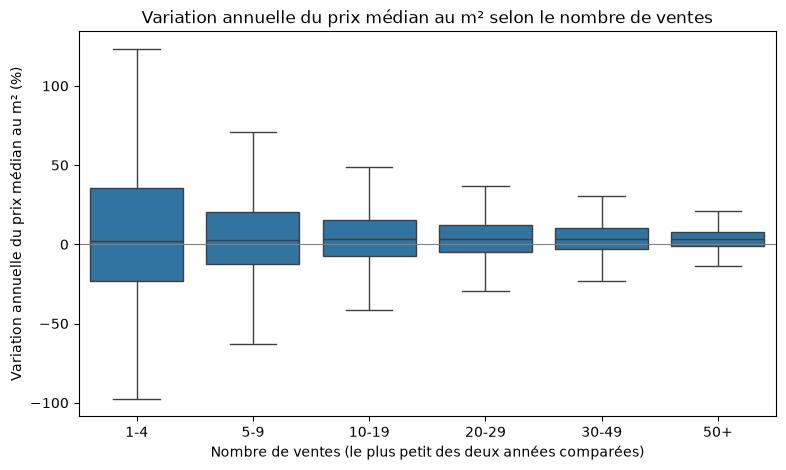

In [10]:
c = cible.sort_values(["code_commune", "annee"]).copy()

# Valeurs de l'année précédente, pour la même commune
c["annee_prec"] = c.groupby("code_commune")["annee"].shift(1)
c["prix_prec"] = c.groupby("code_commune")["prix_m2_median"].shift(1)
c["nb_prec"] = c.groupby("code_commune")["nb_ventes"].shift(1)

# On ne garde que deux années qui se suivent (pas de trou dans la série)
c = c[c["annee"] - c["annee_prec"] == 1].copy()
c["variation"] = (c["prix_m2_median"] / c["prix_prec"] - 1) * 100

# Classe selon le plus petit nombre de ventes des deux années comparées
c["nb_min"] = c[["nb_ventes", "nb_prec"]].min(axis=1)
c["classe"] = pd.cut(c["nb_min"], bins=[0, 4, 9, 19, 29, 49, np.inf],
                     labels=["1-4", "5-9", "10-19", "20-29", "30-49", "50+"])

# Dispersion de la variation dans chaque classe
resume = c.groupby("classe", observed=True)["variation"].describe(percentiles=[0.25, 0.5, 0.75])
resume["IQR"] = resume["75%"] - resume["25%"]
display(resume[["count", "25%", "50%", "75%", "IQR"]].round(1))

# Graphique
plt.figure(figsize=(9, 5))
sns.boxplot(data=c, x="classe", y="variation", showfliers=False)
plt.axhline(0, color="grey", lw=0.8)
plt.xlabel("Nombre de ventes (le plus petit des deux années comparées)")
plt.ylabel("Variation annuelle du prix médian au m² (%)")
plt.title("Variation annuelle du prix médian au m² selon le nombre de ventes")
plt.show()

**Résultat :** quand il y a peu de ventes, la variation annuelle du prix médian change beaucoup d'une année sur l'autre. C'est le cas d'une grande partie des communes : 46 % des comparaisons d'une année à l'autre portent sur moins de 5 ventes.

**Interprétation :** les prix augmentent d'environ 3 % par an. Avec 10 à 19 ventes, l'écart interquartile est de 22,5 points, donc bien plus grand que cette hausse. Dans les petites communes, la variation du prix médian dépend surtout des quelques biens vendus dans l'année, et pas du marché. On ne voit pas de seuil évident sur le graphique : il faudra choisir entre garder beaucoup de communes et avoir une cible fiable.

**Avis métier :** la DGFiP conseille, quand il y a peu de ventes, d'élargir la zone ou la période étudiée plutôt que de se baser sur quelques ventes.

**Impact projet :** la cible par commune et par année n'est fiable que pour une partie des communes. Le seuil choisi fixe le nombre de communes que le modèle pourra prédire.

**Action envisagée :** Etudier en groupe trois options : un seuil de 10 ventes, un seuil de 20 ventes, ou regrouper les petites communes (bassin de vie, ou médiane sur 2 ou 3 ans). La dernières méthode est celle préconisée par le DGFip mais demande un travail plus conséquent.

# C. Relation avec la cible

On travaille sur l'échantillon d'apprentissage (835 288 ventes, 2014-2023), après avoir appliqué les règles d'exclusion de A1. On ne met pas de poids : la médiane du prix au m² change d'environ 1 % avec ou sans poids.

In [11]:
ech = pd.read_parquet(Path("/home/naude/formation/projet_compagnon/data/dvf_plus_echantillon_apprentissage.parquet"))
ech = regles_exclusion(ech, afficher=True)

Ventes au départ           : 835288
Valeur foncière présente   : 834956
Prix au m² >= 50 €         : 833087
Prix au m² <= 50 000 €     : 833028


### C1. Prix au m² selon la surface

**Variables :** `prix_m2`, `sbati`, `type_bien`.

**Pourquoi regarder cela :** la surface est la principale information sur le logement dans DVF+. On veut savoir si le prix au m² change avec la surface, et de quelle façon.

**Méthode :** on découpe la surface en tranches, puis on trace un boxplot du prix au m² pour chaque tranche, en séparant maisons et appartements. Les valeurs extrêmes ne sont pas affichées pour que le graphique reste lisible. Un nuage de points n'a pas été retenu : avec plus de 800 000 ventes, les points se superposent et le graphique risque d'être illisible.

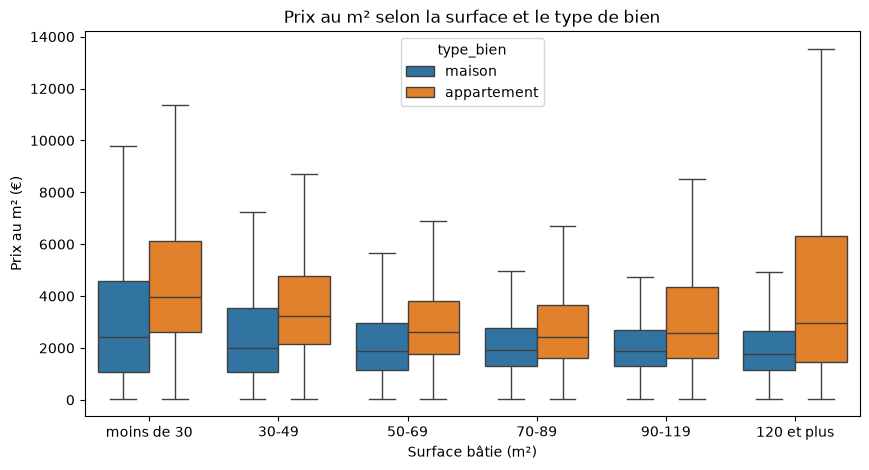

type_bien,appartement,maison
tranche_surface,,
moins de 30,3963.0,2429.0
30-49,3217.0,2000.0
50-69,2615.0,1894.0
70-89,2427.0,1915.0
90-119,2574.0,1886.0
120 et plus,2947.0,1766.0


In [12]:
# Tranches de surface
tranches = [0, 30, 50, 70, 90, 120, np.inf]
noms = ["moins de 30", "30-49", "50-69", "70-89", "90-119", "120 et plus"]
ech["tranche_surface"] = pd.cut(ech["sbati"], bins=tranches, labels=noms, right=False)

# Boxplot du prix au m² par tranche et par type de bien
plt.figure(figsize=(10, 5))
sns.boxplot(data=ech, x="tranche_surface", y="prix_m2", hue="type_bien", showfliers=False)
plt.xlabel("Surface bâtie (m²)")
plt.ylabel("Prix au m² (€)")
plt.title("Prix au m² selon la surface et le type de bien")
plt.show()

# Prix médian par tranche, pour les chiffres du constat
ech.groupby(["tranche_surface", "type_bien"], observed=True)["prix_m2"].median().unstack().round(0)

**Constat :**
- Pour les appartements, le prix médian au m² baisse quand la surface augmente, de 3 950 € environ pour moins de 30 m² à 2 400 € environ pour 70-89 m², puis remonte pour les plus grands (environ 2 950 € au-delà de 120 m²).
- Pour les maisons, le prix médian au m² baisse un peu entre les très petites maisons et les autres, puis reste presque stable, autour de 1 800 à 1 900 €.
- Dans chaque tranche, le prix médian au m² des appartements est plus élevé que celui des maisons.
- L'écart interquartile est plus grand pour les appartements, surtout pour les plus de 120 m².

**Hypothèse :** le prix au m² diminue quand la surface augmente.
- H0 : il n'y a pas de lien entre la surface et le prix au m².
- H1 : le prix au m² change avec la surface.

**Méthode de vérification :** corrélation de Spearman entre la surface et le prix au m², séparément pour les maisons et pour les appartements.

In [13]:
for t in ["appartement", "maison"]:
    d = ech[ech["type_bien"] == t]
    rho, p = stats.spearmanr(d["sbati"], d["prix_m2"])
    print(f"{t} : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(d)}")

appartement : rho = -0.22 | p-value = 0.0e+00 | n = 352624
maison : rho = -0.04 | p-value = 6.4e-197 | n = 480404


**Résultat :** pour les deux types de bien, la p-value est inférieure à 0,05 : on rejette H0, il existe un lien entre la surface et le prix au m². Ce lien est négatif (le prix au m² baisse quand la surface augmente) et faible : rho = -0,22 pour les appartements, et rho = -0,04 pour les maisons, où il est presque nul.

**Interprétation :** pour les appartements, les petits logements sont plus chers au m². Mais le lien n'est pas en ligne droite : le prix baisse jusqu'à 70-89 m², puis remonte pour les grands appartements. Pour les maisons, la surface ne change presque pas le prix au m². Dans les deux cas, la surface explique peu de chose à elle seule. Les écarts entre maisons et appartements, et la forte dispersion des grands appartements, viennent probablement de la localisation : les appartements sont surtout dans les villes, où les prix sont plus élevés.

**Avis métier :** une explication courante est que, dans un petit appartement, la cuisine et la salle de bain coûtent aussi cher que dans un grand, mais sont réparties sur moins de m². Les petites surfaces sont aussi très demandées (étudiants, investissement locatif).

**Impact projet :** la cible est un prix médian par commune. Elle dépend donc aussi de la taille et du type des logements vendus dans l'année : si une commune vend plus de studios une année, son prix médian au m² peut monter sans que le marché ait changé.

**Action envisagée :** garder la surface et le type de bien comme variables, sans supposer un lien en ligne droite (par exemple en tranches). Vérifier l'effet de la localisation avec la carte (B3).

**Biais / limites :** Spearman ne mesure qu'un lien dans un seul sens, alors que la courbe des appartements baisse puis remonte. Le graphique mélange tous les territoires. Pour les maisons, le prix inclut le terrain, mais la surface ne compte que le bâti.

### C2. Prix au m² selon le type de biens

**Variables :** `prix_m2`, `type_bien`.

**Pourquoi regarder cela :** les maisons et les appartements sont les deux types de biens de notre périmètre. On veut savoir si leurs prix au m² sont différents, pour décider s'il faut les traiter séparément dans le modèle.

**Méthode :** histogramme du prix au m² pour chaque type de bien, d'abord en échelle normale, puis en échelle log.

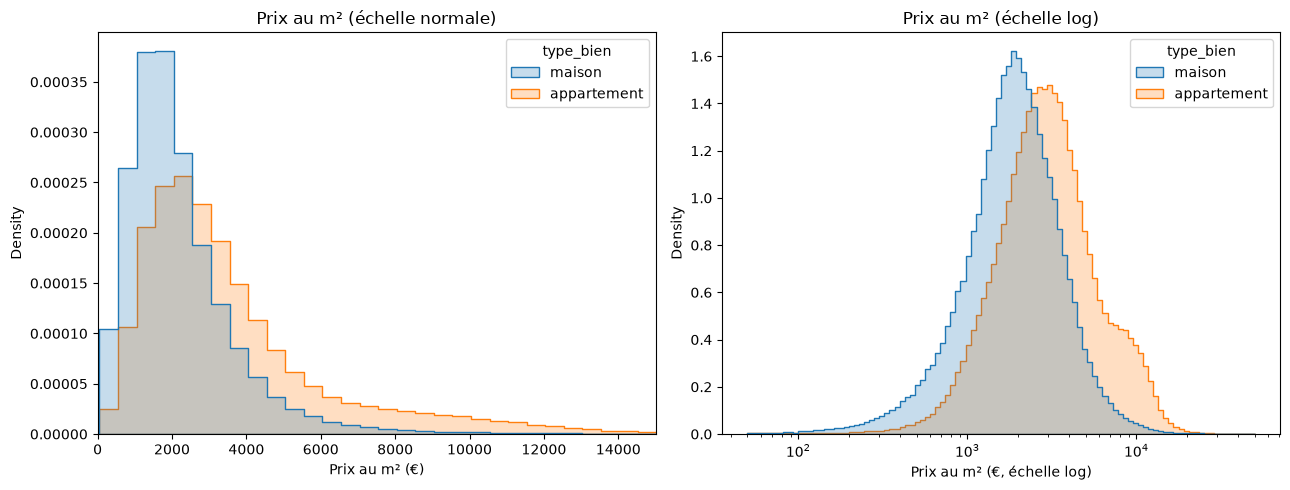

type_bien
appartement    2891.0
maison         1870.0
Name: prix_m2, dtype: float64

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Échelle normale, limitée à 15 000 €/m² pour la lisibilité
sns.histplot(data=ech, x="prix_m2", hue="type_bien", bins=100, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_xlim(0, 15000)
axes[0].set_title("Prix au m² (échelle normale)")
axes[0].set_xlabel("Prix au m² (€)")

# Échelle log
sns.histplot(data=ech, x="prix_m2", hue="type_bien", bins=100, stat="density",
             common_norm=False, element="step", log_scale=True, ax=axes[1])
axes[1].set_title("Prix au m² (échelle log)")
axes[1].set_xlabel("Prix au m² (€, échelle log)")

plt.tight_layout()
plt.show()

# Médianes par type
ech.groupby("type_bien")["prix_m2"].median().round(0)# analyse / visualisation

**Constat :**
- En échelle normale, les deux distributions sont très étirées vers la droite : beaucoup de ventes entre 1 000 et 3 000 € au m², et quelques ventes très chères.
- En échelle log, les deux distributions deviennent à peu près symétriques.
- Le prix au m² des appartements est plus élevé que celui des maisons : environ 2 900 € de médiane contre 1 900 €.
- La distribution des appartements a une bosse vers 8 000 à 10 000 € au m².

**Hypothèse :**
- H0 : les prix au m² des maisons et des appartements ont la même distribution.
- H1 : les prix au m² des maisons et des appartements sont différents.

**Méthode de vérification :** test de Mann-Whitney, qui compare deux groupes sans supposer que les données suivent une loi normale. On regarde aussi l'écart entre les médianes.

In [15]:
appart = ech.loc[ech["type_bien"] == "appartement", "prix_m2"]
maison = ech.loc[ech["type_bien"] == "maison", "prix_m2"]

U, p, r = r_mannwhitney(appart, maison)
print(f"Mann-Whitney : p-value = {p:.1e} | r = {r:.2f}")
print(f"Probabilité qu'un appartement soit plus cher au m² qu'une maison : {(1 + r) / 2:.0%}")
print(f"Écart des médianes : {appart.median() - maison.median():.0f} €/m²")

Mann-Whitney : p-value = 0.0e+00 | r = 0.39
Probabilité qu'un appartement soit plus cher au m² qu'une maison : 69%
Écart des médianes : 1022 €/m²


**Résultat :** la p-value est inférieure à 0,05 : on rejette H0, les prix au m² des maisons et des appartements sont différents. L'écart des médianes est de 1 022 € au m², en faveur des appartements.

**Interprétation :** les maisons et les appartements forment deux marchés différents. L'échelle log rend les distributions à peu près symétriques, ce qui sera utile pour le modèle. La bosse des appartements vers 8 000 à 10 000 € au m² correspond probablement aux grandes villes chères, surtout Paris.

**Avis métier :** les appartements se trouvent surtout dans les villes, où les prix sont élevés. Les maisons sont plus souvent en zone périurbaine ou rurale, où les prix sont plus bas. L'écart vient donc en partie de la localisation, et pas seulement du type de bien.

**Impact projet :** la cible mélange maisons et appartements. Si la part de maisons vendues change d'une année à l'autre dans une commune, le prix médian au m² peut changer sans que les prix aient bougé.

**Action envisagée :** discuter en groupe de deux options : calculer une cible séparée pour les maisons et pour les appartements, ou garder une cible commune et ajouter la part de maisons comme variable. Utiliser le log du prix au m² pour le modèle.

**Biais / limites :** la comparaison mélange tous les territoires. L'échantillon est utilisé sans poids.

### C3. Prix au m² selon le département

**Variables :** `prix_m2`, `coddep`, part d'appartements dans les ventes (calculée à partir de `type_bien`).

**Pourquoi regarder cela :** on a vu en B1 et B2 que la localisation semble expliquer une grande partie des écarts de prix. On veut voir comment le prix au m² varie d'un département à l'autre, et si ces écarts sont liés à la part d'appartements vendus.

**Méthode :**
1. carte du prix médian au m² par département ;
2. carte de la part d'appartements dans les ventes, et nuage de points (un point par département) entre cette part et le prix médian.

Les calculs portent sur la population complète (après les règles de A1), pour avoir assez de ventes dans chaque département.

Départements sans données : ['Moselle', 'Bas-Rhin', 'Haut-Rhin']


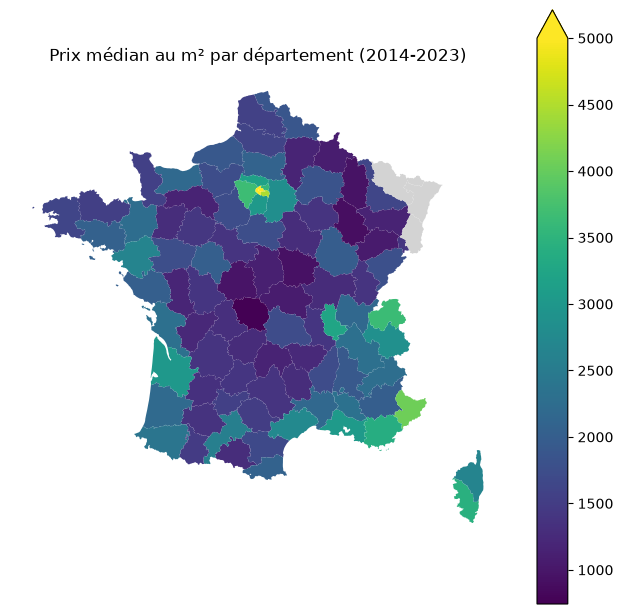

   coddep  prix_m2_median
21     23           743.0
52     52           909.0
57     58           938.0
55     55           946.0
36     36           973.0
75     78          3667.0
5      06          4062.0
91     94          4479.0
89     92          6288.0
72     75          9511.0


In [16]:
import geopandas as gpd

# Contours des départements (dépôt GitHub france-geojson)
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
deps = gpd.read_file(url)

# Prix médian au m² par département, sur la population
med_dep = ventes.groupby("coddep")["prix_m2"].median().reset_index(name="prix_m2_median")

# Jointure sur le code département (texte des deux côtés)
deps = deps.merge(med_dep, left_on="code", right_on="coddep", how="left")
print("Départements sans données :", deps.loc[deps["prix_m2_median"].isna(), "nom"].tolist())

# Carte
ax = deps.plot(column="prix_m2_median", cmap="viridis", legend=True, vmax=5000,
               missing_kwds={"color": "lightgrey"}, figsize=(8, 8))
ax.set_axis_off()
ax.set_title("Prix médian au m² par département (2014-2023)")
plt.show()

# Les 5 départements les plus chers et les 5 moins chers
print(med_dep.sort_values("prix_m2_median").iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]].round(0))

**Constat :**
- Le prix médian au m² varie beaucoup d'un département à l'autre : de 743 € dans la Creuse à 9 511 € à Paris, soit environ 13 fois plus.
- Les départements les plus chers sont Paris (9 511 €), les Hauts-de-Seine (6 288 €), le Val-de-Marne (4 479 €), les Alpes-Maritimes (4 062 €) et les Yvelines (3 667 €).
- Les moins chers sont la Creuse (743 €), la Haute-Marne (909 €), la Nièvre (938 €), la Meuse (946 €) et l'Indre (973 €).
- Les prix élevés se trouvent en Île-de-France, sur la côte méditerranéenne, dans les Alpes et autour des grandes villes. Les prix bas forment une bande du nord-est au centre de la France.
- L'Alsace-Moselle (Bas-Rhin, Haut-Rhin, Moselle) n'a pas de données.
- Sur la carte, l'échelle de couleur s'arrête à 5 000 € : Paris et les Hauts-de-Seine dépassent cette valeur.

**Hypothèse :**
- H0 : le prix au m² a la même distribution dans tous les départements.
- H1 : le prix au m² est différent selon les départements.

**Méthode de vérification :** test de Kruskal-Wallis, qui compare plus de deux groupes sans supposer une loi normale. C'est l'équivalent de Mann-Whitney pour plusieurs groupes.

In [17]:
groupes = [g["prix_m2"].values for _, g in ventes.groupby("coddep")]

H, p, eta2 = eta2_kruskal(groupes)
print(f"Kruskal-Wallis : p-value = {p:.1e} | eta² = {eta2:.3f} | nombre de départements = {len(groupes)}")

Kruskal-Wallis : p-value = 0.0e+00 | eta² = 0.479 | nombre de départements = 93


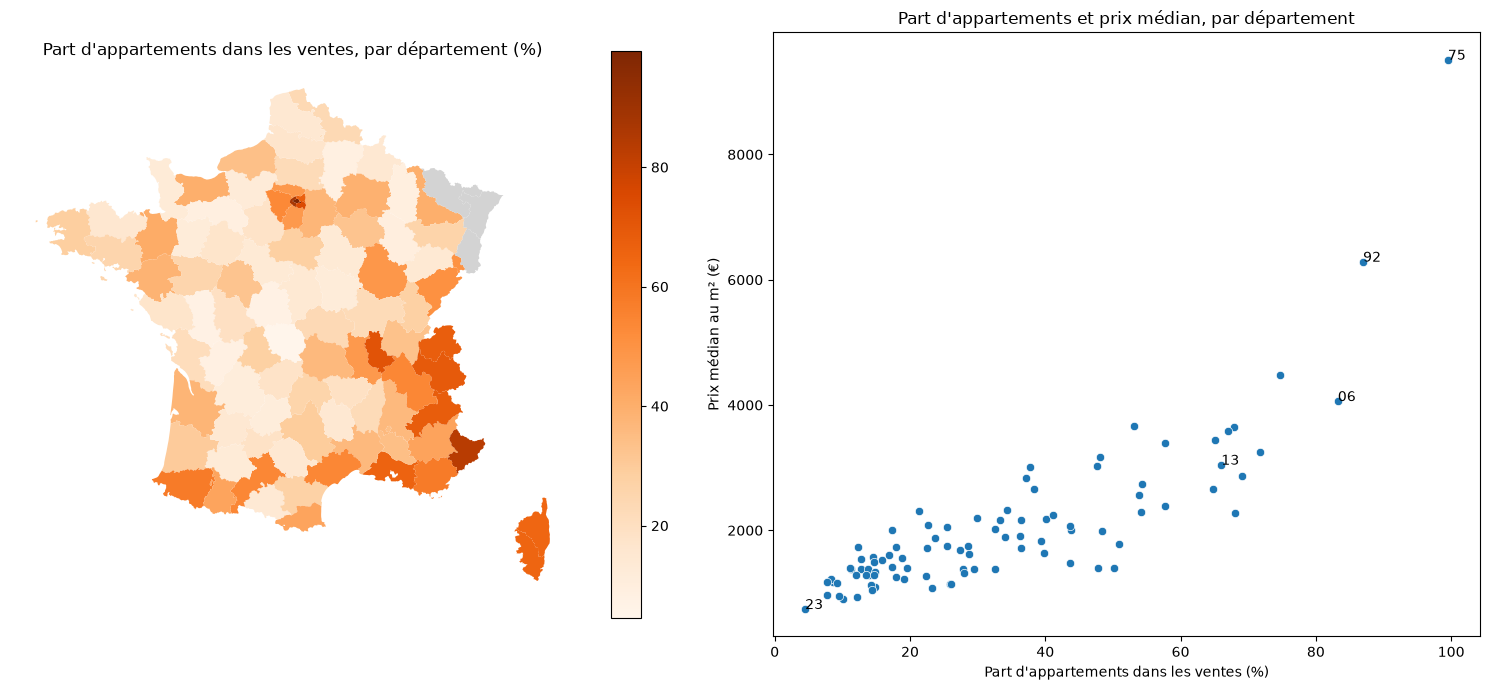

In [18]:
# Part d'appartements et prix médian par département (population)
dep = (ventes.groupby("coddep")
             .agg(nb_ventes=("prix_m2", "size"),
                  part_maisons=("est_maison", "mean"),
                  prix_m2_median=("prix_m2", "median"))
             .reset_index())
dep["part_appart (%)"] = (1 - dep["part_maisons"]) * 100

# Contours des départements (déjà chargés en B3) + nouvelles données
carte_part = deps[["code", "nom", "geometry"]].merge(dep, left_on="code", right_on="coddep", how="left")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Carte de la part d'appartements
carte_part.plot(column="part_appart (%)", cmap="Oranges", legend=True,
                missing_kwds={"color": "lightgrey"}, ax=axes[0])
axes[0].set_axis_off()
axes[0].set_title("Part d'appartements dans les ventes, par département (%)")

# Un point par département : part d'appartements et prix médian
sns.scatterplot(data=dep, x="part_appart (%)", y="prix_m2_median", ax=axes[1])
for d in ["75", "92", "06", "23", "13"]:
    ligne = dep[dep["coddep"] == d]
    axes[1].annotate(d, (ligne["part_appart (%)"].iloc[0], ligne["prix_m2_median"].iloc[0]))
axes[1].set_xlabel("Part d'appartements dans les ventes (%)")
axes[1].set_ylabel("Prix médian au m² (€)")
axes[1].set_title("Part d'appartements et prix médian, par département")

plt.tight_layout()
plt.show()


**Constat :**
- La part d'appartements dans les ventes varie beaucoup selon les départements : moins de 10 % dans la Creuse, près de 100 % à Paris. Elle est forte en Île-de-France, sur la côte méditerranéenne, dans les Alpes et autour des grandes villes.
- Plus la part d'appartements est élevée, plus le prix médian au m² du département est élevé : les points forment presque une droite.

**Hypothèse :**
- H0 : il n'y a pas de lien entre la part d'appartements vendus et le prix médian au m² du département.
- H1 : le prix médian au m² change avec la part d'appartements.

**Méthode de vérification :** corrélation de Spearman sur les 93 départements.

In [19]:
for t in ["maison", "appartement"]:
    groupes = [g["prix_m2"].values for _, g in ventes[ventes["type_bien"] == t].groupby("coddep")]
    H, p, eta2 = eta2_kruskal(groupes)
    print(f"{t} : p-value = {p:.1e} | eta² = {eta2:.3f} | {len(groupes)} départements")

maison : p-value = 0.0e+00 | eta² = 0.373 | 93 départements
appartement : p-value = 0.0e+00 | eta² = 0.523 | 93 départements


**Résultat :**
- **Kruskal-Wallis, toutes ventes** : la p-value est inférieure à 0,05, on rejette H0 : le prix au m² est différent selon les départements. La taille d'effet est forte (η² = 0,48) : le département explique à lui seul près de la moitié des écarts de prix au m². Le prix médian va de 743 € (Creuse) à 9 511 € (Paris), soit un rapport d'environ 13.
- **Kruskal-Wallis, par type de bien** : l'effet reste fort pour les deux types, plus pour les appartements (η² = 0,52) que pour les maisons (η² = 0,37).
- **Spearman** : la p-value est inférieure à 0,05, on rejette H0. Le lien entre la part d'appartements et le prix médian du département est positif et fort (rho = 0,82, 93 départements).

**Interprétation :** la localisation est le facteur le plus fort parmi ceux étudiés : son effet (η² = 0,48) est bien plus grand que celui du type de bien (C2, r = 0,39, effet moyen) ou de la surface (C1, effet faible ou négligeable). L'effet du département reste fort quand on sépare maisons et appartements : il ne vient donc pas seulement du fait que les départements chers vendent plus d'appartements. Il est plus fort pour les appartements, dont les prix varient énormément entre les grandes villes chères (Paris en tête) et les villes moyennes.

Les départements chers sont aussi ceux où l'on vend le plus d'appartements. Ce n'est pas la part d'appartements qui fait monter les prix : dans les zones denses et attractives, le terrain est rare et cher, on construit donc plus d'immeubles, et les prix sont élevés pour tous les logements. Cela confirme qu'une partie de l'écart entre maisons et appartements vu en C2 vient de leur localisation.

**Avis métier :** les prix sont élevés là où il y a de l'emploi et une forte demande (Île-de-France, grandes villes), et dans les zones touristiques (littoral méditerranéen, Alpes). Ils sont bas dans les territoires peu denses qui perdent des habitants, souvent appelés la « diagonale du vide ».

**Impact projet :** le territoire doit être au centre du modèle. Les variables des autres bases du projet (ménages, logements, bassins de vie) devraient aider à expliquer ces écarts.

**Action envisagée :** garder la localisation dans le modèle et la compléter par des variables territoriales issues des autres bases.

**Biais / limites :** le département est une maille large, qui cache de grands écarts à l'intérieur (par exemple Megève et le reste de la Haute-Savoie). L'Alsace-Moselle n'est pas couverte : le modèle ne pourra pas y faire de prédiction. Sur la carte, l'échelle de couleur est limitée à 5 000 €.

### C4. Évolution du prix au m² et du nombre de ventes dans le temps

**Variables :** `prix_m2`, `datemut`, `type_bien`.

**Pourquoi regarder cela :** le projet porte sur l'évolution des prix. On veut voir comment le prix au m² et le nombre de ventes ont évolué entre 2014 et 2023.

**Méthode :** nombre de ventes par trimestre, pour les maisons et pour les appartements, calculés sur la population (après les règles de A1) ainsi que l'évolution du prix au m² par trimestre.

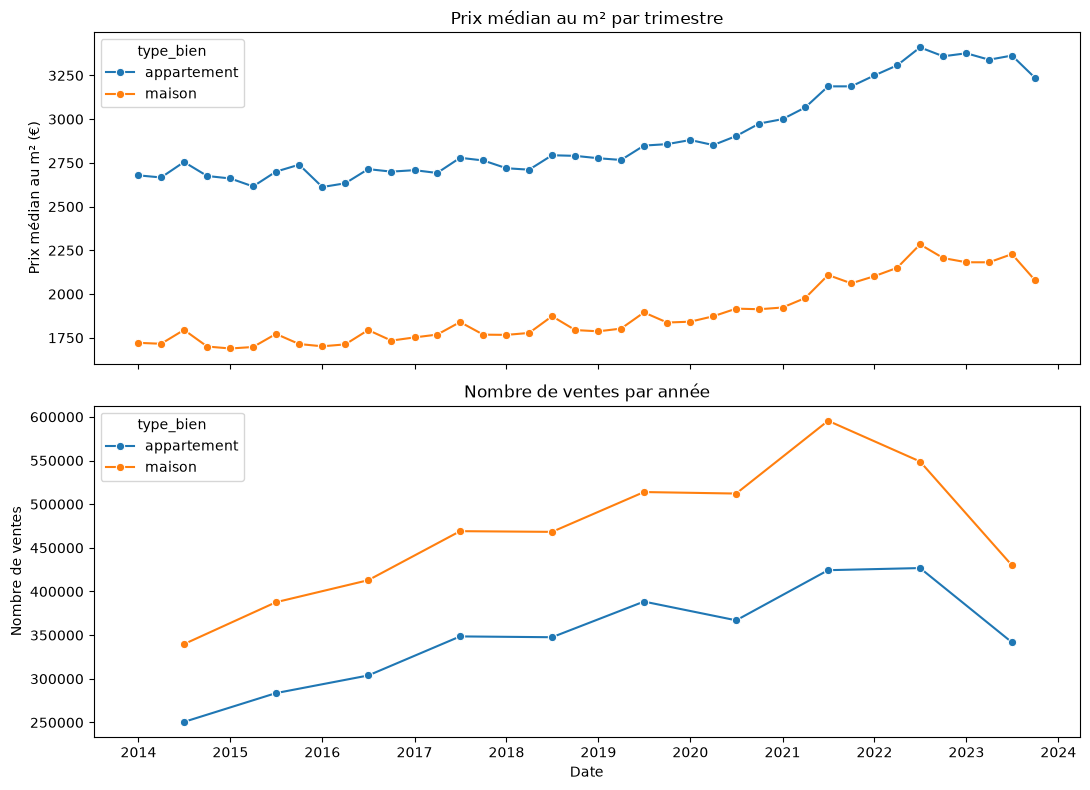

In [20]:
# Trimestre de chaque vente
ventes["trimestre"] = pd.to_datetime(ventes["datemut"], format="%Y-%m-%d").dt.to_period("Q")

# Prix médian par trimestre et par type
trim = (ventes.groupby(["trimestre", "type_bien"])["prix_m2"]
              .median().reset_index(name="prix_m2_median"))
trim["trimestre"] = trim["trimestre"].dt.to_timestamp()   # format date, pour l'axe du graphique

# Nombre de ventes par année et par type
annuel = ventes.groupby(["anneemut", "type_bien"]).size().reset_index(name="nb_ventes")
annuel["date"] = pd.to_datetime(annuel["anneemut"].astype(str) + "-07-01")   # point placé au milieu de l'année

# Deux graphiques l'un au-dessus de l'autre, avec le même axe du temps
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

sns.lineplot(data=trim, x="trimestre", y="prix_m2_median", hue="type_bien", marker="o", ax=axes[0])
axes[0].set_ylabel("Prix médian au m² (€)")
axes[0].set_title("Prix médian au m² par trimestre")

sns.lineplot(data=annuel, x="date", y="nb_ventes", hue="type_bien", marker="o", ax=axes[1])
axes[1].set_ylabel("Nombre de ventes")
axes[1].set_title("Nombre de ventes par année")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

**Résultat :** on distingue trois périodes :
- de 2014 à 2018, les prix sont presque stables, et le nombre de ventes augmente ;
- de 2019 à 2022, les prix augmentent nettement et le nombre de ventes atteint un pic en 2021 (plus d'un million de ventes) ;
- en 2023, le nombre de ventes baisse de 21 % et les prix baissent légèrement.


**Interprétation :** la période compte beaucoup : selon les années, les prix et les ventes ne suivent pas la même tendance. Les prix réagissent avec un temps de retard : ils continuent de monter en 2022 alors que les ventes commencent déjà à baisser.

**Avis métier :** ces évolutions sont liées au contexte économique (taux des crédits, confinement de 2020). Le lien avec les taux sera étudié dans la partie sur les autres sources de données.

**Impact projet :** un modèle qui ne verrait qu'une seule période (par exemple les années de hausse) risquerait de mal prédire une période de baisse. Les données d'entraînement et de test devront être séparées par date, comme le recommande le cours sur les séries temporelles.

**Action envisagée :** garder toute la période 2014-2023 pour l'entraînement. Étudier le lien avec les taux d'intérêt dans la partie sur les autres sources.

**Biais / limites :** le prix médian national mélange tous les territoires et dépend du type de biens vendus chaque année. Les années 2024 et 2025 n'ont pas été regardées.

In [21]:
# Sauvegarde du prix médian par trimestre, pour le croisement avec les taux dans l'EDA Filosofi
trim.to_csv("/home/naude/formation/projet_compagnon/data/prix_m2_median_trimestre.csv", index=False)

### C5. Prix au m² selon le nombre de pièces

**Variables :** `prix_m2`, nombre de pièces (construit à partir de `nbapt1pp` à `nbapt5pp` et `nbmai1pp` à `nbmai5pp`), `type_bien`.

**Pourquoi regarder cela :** le nombre de pièces est un des premiers critères d'un acheteur. On veut savoir si le prix au m² change avec le nombre de pièces.

**Méthode :** on construit une variable « nombre de pièces », puis on trace un boxplot du prix au m² pour chaque nombre de pièces, en séparant maisons et appartements.

In [22]:
# Nombre de pièces de chaque vente, à partir des colonnes de DVF+
# nbapt1pp = nombre d'appartements d'1 pièce, ..., nbapt5pp = 5 pièces et plus (idem pour les maisons)
# Chaque vente porte sur un seul logement : une seule de ces colonnes vaut 1
ech["nb_pieces"] = 0
for k in range(1, 6):
    ech["nb_pieces"] += k * (ech[f"nbapt{k}pp"] + ech[f"nbmai{k}pp"])

print(ech["nb_pieces"].value_counts().sort_index())

nb_pieces
1     71097
2    135595
3    202825
4    218300
5    205211
Name: count, dtype: int64


Ventes sans nombre de pièces : 0


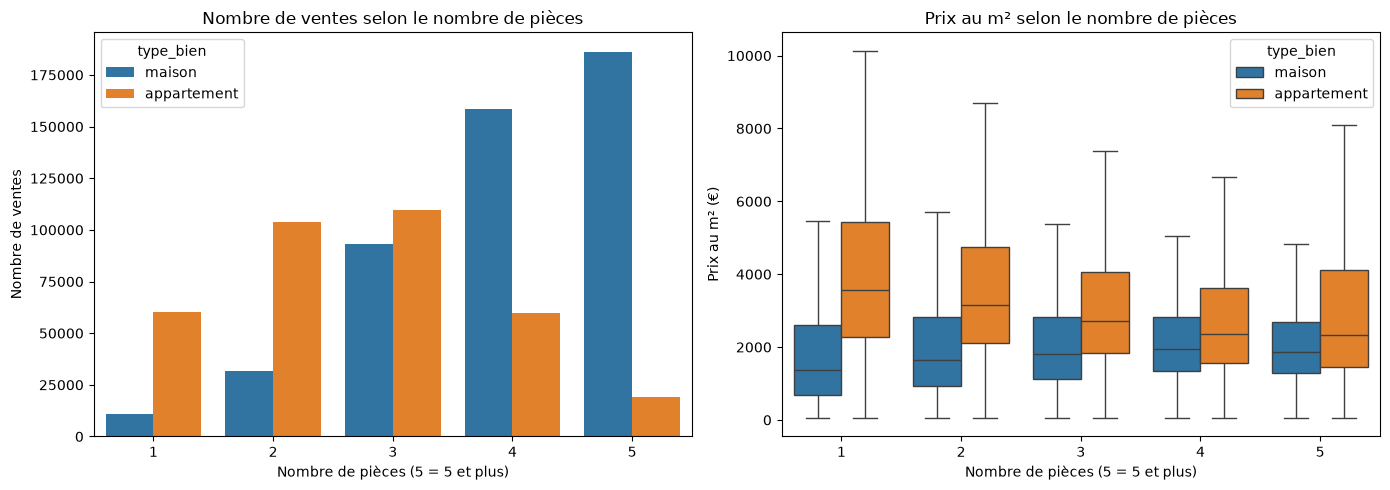

type_bien,appartement,maison
nb_pieces,,
1,3556.0,1380.0
2,3159.0,1644.0
3,2727.0,1812.0
4,2370.0,1960.0
5,2333.0,1862.0


In [23]:
# Ventes sans nombre de pièces renseigné : on les compte, puis on les écarte du graphique
print("Ventes sans nombre de pièces :", (ech["nb_pieces"] == 0).sum())
p = ech[ech["nb_pieces"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Répartition des ventes
sns.countplot(data=p, x="nb_pieces", hue="type_bien", hue_order=["maison", "appartement"], ax=axes[0])
axes[0].set_title("Nombre de ventes selon le nombre de pièces")
axes[0].set_xlabel("Nombre de pièces (5 = 5 et plus)")
axes[0].set_ylabel("Nombre de ventes")

# Prix au m² selon le nombre de pièces
sns.boxplot(data=p, x="nb_pieces", y="prix_m2", hue="type_bien", hue_order=["maison", "appartement"],
            showfliers=False, ax=axes[1])
axes[1].set_title("Prix au m² selon le nombre de pièces")
axes[1].set_xlabel("Nombre de pièces (5 = 5 et plus)")
axes[1].set_ylabel("Prix au m² (€)")

plt.tight_layout()
plt.show()

# Prix médian par nombre de pièces et par type
p.groupby(["nb_pieces", "type_bien"])["prix_m2"].median().unstack().round(0)

**Constat :**
- Pour les appartements, le nombre de ventes suit une courbe en cloche : peu de 1 pièce, beaucoup de 2 et 3 pièces, peu de 5 pièces et plus.
- Pour les maisons, le nombre de ventes augmente avec le nombre de pièces. La dernière catégorie regroupe toutes les maisons de 5 pièces et plus, ce qui explique en partie qu'elle soit la plus grande.
- Pour les appartements, le prix médian au m² baisse quand le nombre de pièces augmente : 3 556 € pour une pièce, 2 333 € pour 5 pièces et plus. Les boîtes sont larges et se décalent d'une catégorie à l'autre.
- Pour les maisons, le prix médian au m² reste assez stable (entre 1 380 € et 1 960 €), et les boîtes se chevauchent beaucoup.

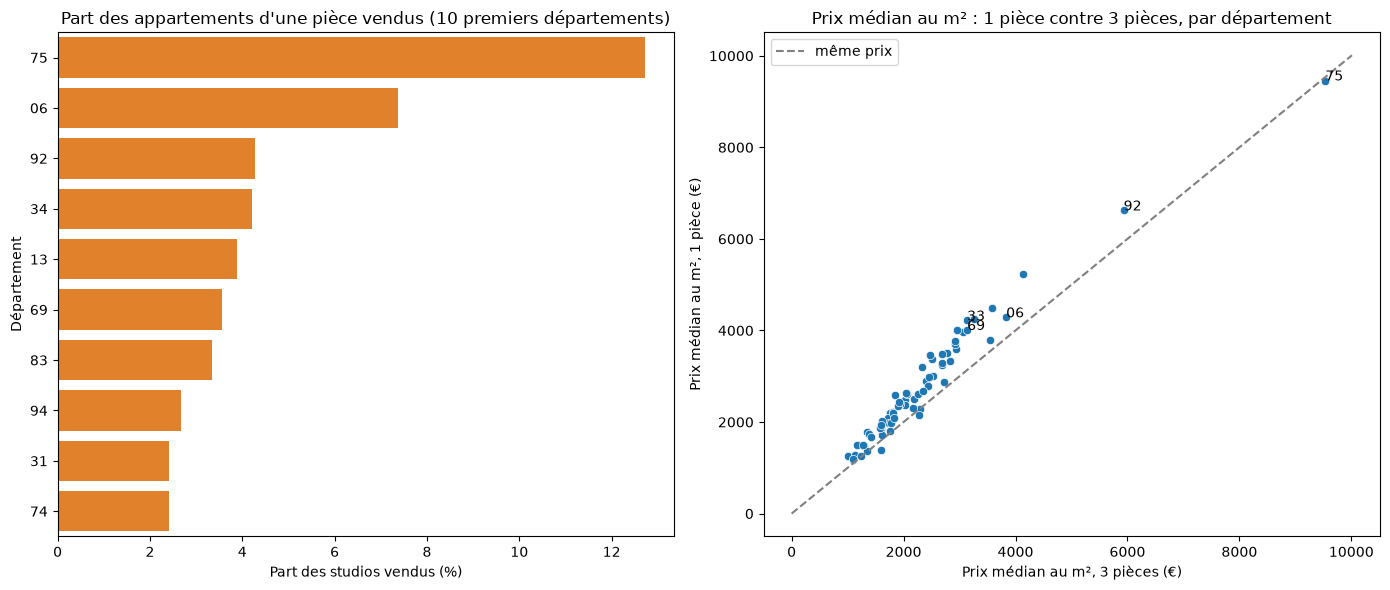

Départements gardés : 68
Départements où le studio est plus cher au m² : 64
Écart médian entre 1 pièce et 3 pièces : 20.5 %


In [24]:
apt = ech[(ech["type_bien"] == "appartement") & (ech["nb_pieces"] > 0)]

# Part des studios vendus par département (10 premiers, en %)
part_1p = (apt[apt["nb_pieces"] == 1]["coddep"].value_counts(normalize=True) * 100).head(10)

# Prix médian au m² par département et nombre de pièces
tab = apt.pivot_table(index="coddep", columns="nb_pieces", values="prix_m2", aggfunc="median")
tab["nb_ventes_1p"] = apt[apt["nb_pieces"] == 1].groupby("coddep").size()
tab = tab[tab["nb_ventes_1p"] >= 100]   # assez de studios pour une médiane fiable
tab["ecart_1p_vs_3p (%)"] = (tab[1] / tab[3] - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Graphique 1 : où sont vendus les studios
sns.barplot(x=part_1p.values, y=part_1p.index, color="tab:orange", ax=axes[0])
axes[0].set_title("Part des appartements d'une pièce vendus (10 premiers départements)")
axes[0].set_xlabel("Part des studios vendus (%)")
axes[0].set_ylabel("Département")

# Graphique 2 : un point par département
sns.scatterplot(data=tab, x=3, y=1, ax=axes[1])
lim = tab[[1, 3]].max().max() * 1.05
axes[1].plot([0, lim], [0, lim], color="grey", linestyle="--", label="même prix")
for dep in ["75", "92", "06", "69", "33"]:     # quelques départements repérés sur le graphique
    if dep in tab.index:
        axes[1].annotate(dep, (tab.loc[dep, 3], tab.loc[dep, 1]))
axes[1].set_title("Prix médian au m² : 1 pièce contre 3 pièces, par département")
axes[1].set_xlabel("Prix médian au m², 3 pièces (€)")
axes[1].set_ylabel("Prix médian au m², 1 pièce (€)")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Départements gardés :", len(tab))
print("Départements où le studio est plus cher au m² :", (tab[1] > tab[3]).sum())
print("Écart médian entre 1 pièce et 3 pièces :", round(tab["ecart_1p_vs_3p (%)"].median(), 1), "%")

In [25]:
for t in ["appartement", "maison"]:
    d = ech[(ech["type_bien"] == t) & (ech["nb_pieces"] > 0)]
    groupes = [g["prix_m2"].values for _, g in d.groupby("nb_pieces")]
    H, p, eta2 = eta2_kruskal(groupes)
    print(f"{t} : Kruskal-Wallis : p-value = {p:.1e} | eta² = {eta2:.3f}")

appartement : Kruskal-Wallis : p-value = 0.0e+00 | eta² = 0.038
maison : Kruskal-Wallis : p-value = 0.0e+00 | eta² = 0.007


**Constat :**
- Les appartements d'une pièce sont concentrés dans les départements chers : Paris représente près de 13 % des studios vendus, suivi des Alpes-Maritimes, des Hauts-de-Seine et des départements des grandes villes.
- Dans presque tous les départements, le prix médian au m² d'un studio est plus élevé que celui d'un 3 pièces (écart médian de 20,5 %).
- Paris est une exception : le studio et le 3 pièces ont presque le même prix médian au m².

**Résultat :**
- Kruskal-Wallis : la p-value est inférieure à 0,05 pour les deux types, on rejette H0 : le prix au m² est différent selon le nombre de pièces. Mais la taille d'effet est faible pour les appartements (η² = 0,04 : le nombre de pièces explique environ 4 % des écarts de prix au m²) et négligeable pour les maisons (η² = 0,007).
- Pour les appartements, plus il y a de pièces, plus le prix au m² baisse. Cet écart vient de deux causes : les studios sont surtout vendus dans les départements chers, et, dans un même département, ils restent plus chers au m².
- Redondance avec la surface : la corrélation de Spearman entre la surface et le nombre de pièces est forte, 0,87 pour les appartements et 0,68 pour les maisons. Pour les appartements, les deux variables portent presque la même information. Pour les maisons, chacune apporte une information en partie différente.

**Interprétation :** le nombre de pièces a un effet propre sur le prix au m² des appartements, qui ne vient pas seulement de la localisation, mais cet effet est faible. Pour les maisons, il est négligeable. On retrouve aussi l'effet de composition vu en C3 : les petits appartements sont vendus surtout là où les prix sont élevés.

**Avis métier :** les studios sont très recherchés (étudiants, jeunes actifs, investissement locatif), et leur cuisine et salle de bain sont réparties sur peu de m². Une maison d'une pièce est souvent une petite maison rurale ou à rénover. À Paris, les grands appartements sont rares, ce qui pourrait expliquer que leur prix au m² rejoigne celui des studios (hypothèse).

**Impact projet :** le prix médian d'une commune dépend aussi du type de logements vendus dans l'année : une année avec beaucoup de studios vendus fera monter le prix médian au m², sans que le marché ait changé.

**Action envisagée :**
- garder le nombre de pièces comme variable candidate secondaire pour les appartements ;
- ne pas garder la surface et le nombre de pièces telles quelles dans un modèle linéaire, car elles sont très redondantes pour les appartements. Tester plutôt une variable « surface par pièce », qui indique si les pièces sont grandes ou petites ;
- vérifier en modélisation si le nombre de pièces apporte une information en plus de la surface.

**Biais / limites :** la catégorie 5 regroupe tous les logements de 5 pièces et plus. La comparaison par département ne garde que les départements avec au moins 100 studios, et le département reste une maille large.

### C6. Prix au m² des maisons selon la surface du terrain

**Variables :** `prix_m2`, `sterr` (surface du terrain, en m²), uniquement pour les maisons.

**Pourquoi regarder cela :** pour une maison, le prix de vente comprend le terrain, alors que le prix au m² ne compte que la surface bâtie. On veut savoir si la taille du terrain change le prix au m².

**Méthode :** on découpe la surface du terrain en tranches, puis on regarde le nombre de ventes et le prix au m² dans chaque tranche.

Part des maisons sans terrain : 4.5 %


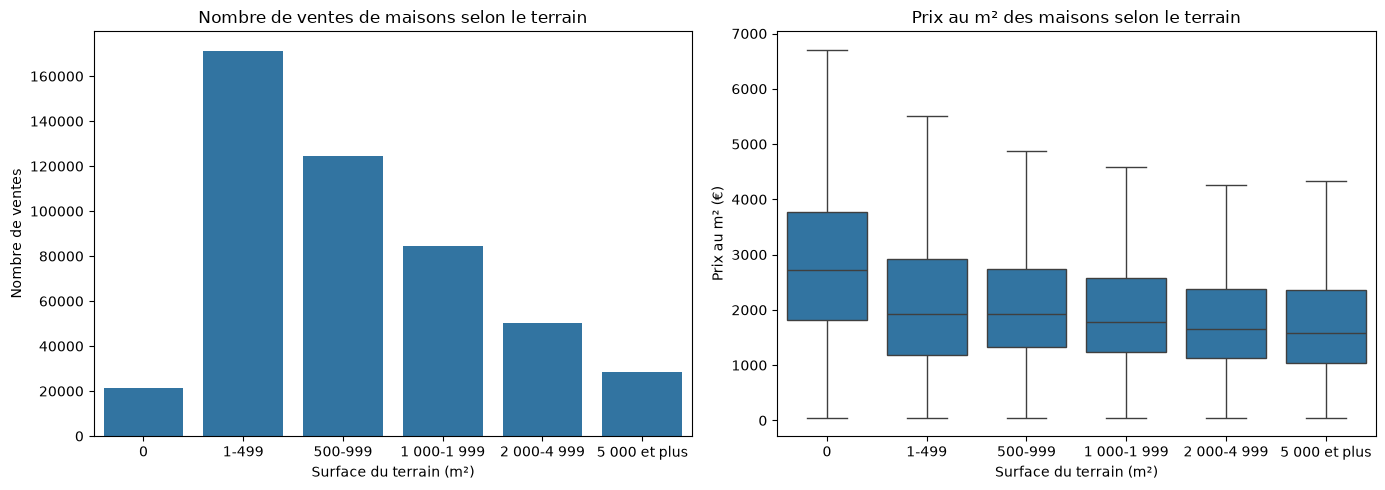

tranche_terrain
0                2721.0
1-499            1917.0
500-999          1932.0
1 000-1 999      1787.0
2 000-4 999      1650.0
5 000 et plus    1576.0
Name: prix_m2, dtype: float64

In [26]:
mai = ech[ech["type_bien"] == "maison"].copy()
print("Part des maisons sans terrain :", round((mai["sterr"] == 0).mean() * 100, 1), "%")

# Tranches de surface de terrain
tranches_t = [0, 1, 500, 1000, 2000, 5000, np.inf]
noms_t = ["0", "1-499", "500-999", "1 000-1 999", "2 000-4 999", "5 000 et plus"]
mai["tranche_terrain"] = pd.cut(mai["sterr"], bins=tranches_t, labels=noms_t, right=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=mai, x="tranche_terrain", color="tab:blue", ax=axes[0])
axes[0].set_title("Nombre de ventes de maisons selon le terrain")
axes[0].set_xlabel("Surface du terrain (m²)")
axes[0].set_ylabel("Nombre de ventes")

sns.boxplot(data=mai, x="tranche_terrain", y="prix_m2", color="tab:blue", showfliers=False, ax=axes[1])
axes[1].set_title("Prix au m² des maisons selon le terrain")
axes[1].set_xlabel("Surface du terrain (m²)")
axes[1].set_ylabel("Prix au m² (€)")

plt.tight_layout()
plt.show()

# Prix médian par tranche
mai.groupby("tranche_terrain", observed=True)["prix_m2"].median().round(0)

**Constat :**
- 4,5 % des maisons vendues ont un terrain de 0 m². Les ventes de maisons sont plus nombreuses pour les petits terrains (moins de 500 m²) et diminuent quand le terrain augmente.
- Le prix médian au m² des maisons sans terrain est le plus élevé (2 721 €). Pour les autres, il baisse doucement quand le terrain augmente, de 1 932 € (500-999 m²) à 1 576 € (5 000 m² et plus).
- Les boîtes se chevauchent beaucoup. La dispersion est plus forte pour les petits terrains.

**Méthode de vérification :** manipulation de données :
1. pour les maisons sans terrain, la part en copropriété (`nblot` > 0) et les départements où elles sont vendues ;
2. pour chaque tranche de terrain, le prix médian du département où les maisons sont vendues (calculé en B3).

In [27]:
# 1. Maisons sans terrain : où sont-elles, et sont-elles en copropriété ?
sans = mai[mai["sterr"] == 0]
print((sans["coddep"].value_counts(normalize=True) * 100).head(10).round(1))
print("En copropriété (nblot > 0) :", round((sans["nblot"] > 0).mean() * 100, 1), "% des maisons sans terrain,",
      "contre", round((mai["nblot"] > 0).mean() * 100, 1), "% de l'ensemble des maisons")

# 2. Les grands terrains sont-ils dans des départements moins chers ?
prix_dep = dep[["coddep", "prix_m2_median"]].rename(columns={"prix_m2_median": "prix_dep"})
mai = mai.merge(prix_dep, on="coddep", how="left")
mai.groupby("tranche_terrain", observed=True)["prix_dep"].median().round(0)

coddep
33    4.9
13    4.4
34    4.4
83    4.2
78    3.5
91    3.4
77    3.3
95    3.2
31    3.2
06    3.0
Name: proportion, dtype: float64
En copropriété (nblot > 0) : 84.5 % des maisons sans terrain, contre 4.6 % de l'ensemble des maisons


TypeError: string indices must be integers, not 'list'

**Résultat :**
- 84,5 % des maisons sans terrain sont en copropriété, contre 4,6 % de l'ensemble des maisons. Elles sont surtout vendues autour des grandes villes et sur le littoral (Gironde, Bouches-du-Rhône, Hérault, Var, grande couronne parisienne).
- Le prix médian du département baisse quand le terrain augmente (de 1 916 € à 1 556 €), presque exactement comme le prix médian des maisons elles-mêmes.

**Interprétation :** un terrain à 0 n'est pas une erreur : la maison est en copropriété et le terrain est commun. La baisse du prix au m² avec la taille du terrain vient de la localisation : les grands terrains se trouvent dans des départements où les prix sont plus bas. À localisation égale, la taille du terrain semble changer peu le prix au m².

**Avis métier :** les grands terrains sont plus courants en zone rurale, où le foncier est moins cher. Les maisons en copropriété (lotissements, résidences) se trouvent plutôt dans les zones urbaines et touristiques, où le terrain est rare.

**Impact projet :** la surface du terrain apporte peu d'information une fois la localisation prise en compte. En revanche, le fait qu'une maison soit en copropriété est une information utile.

**Action envisagée :** créer une variable « maison en copropriété » (terrain à 0 ou `nblot` > 0). Ne pas traiter un terrain à 0 comme une valeur manquante.

**Biais / limites :** la localisation est mesurée au niveau du département, une maille large. À l'échelle de la commune, la taille du terrain pourrait avoir un effet que cette analyse ne montre pas.

### C7. Prix au m² selon le nombre de dépendances

**Variables :** `prix_m2`, `nblocdep` (nombre de dépendances : garage, cave, parking…), `type_bien`.

**Pourquoi regarder cela :** une dépendance augmente le prix de vente sans ajouter de surface habitable. On veut savoir si elle change le prix au m².

**Méthode :**
1. répartition des ventes et prix au m² selon le nombre de dépendances, pour les maisons et les appartements ;
2. comparaison avec le prix médian du département, pour séparer l'effet des dépendances de celui de la localisation.

type_bien   appartement  maison
dep_classe                     
0                  39.8    84.9
1                  42.1    11.2
2                  14.6     3.1
3 et plus           3.5     0.9
type_bien   appartement  maison
dep_classe                     
0                2864.0  1840.0
1                2879.0  2095.0
2                2950.0  2037.0
3 et plus        3056.0  1943.0


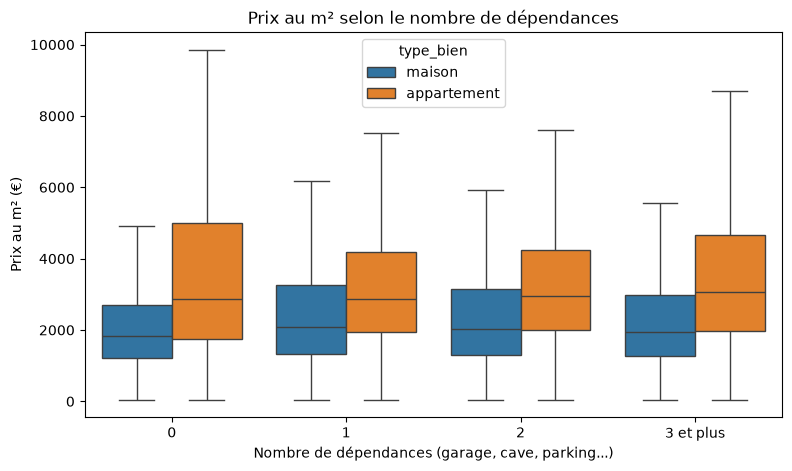

In [ ]:
# Classes de dépendances : 0, 1, 2, 3 et plus
ech["dep_classe"] = pd.cut(ech["nblocdep"], bins=[-1, 0, 1, 2, np.inf],
                           labels=["0", "1", "2", "3 et plus"])

# Répartition des ventes (en % de chaque type de bien)
print((pd.crosstab(ech["dep_classe"], ech["type_bien"], normalize="columns") * 100).round(1))

# Prix médian au m² selon le nombre de dépendances
print(ech.groupby(["dep_classe", "type_bien"], observed=True)["prix_m2"].median().unstack().round(0))

# Boxplot
plt.figure(figsize=(9, 5))
sns.boxplot(data=ech, x="dep_classe", y="prix_m2", hue="type_bien", hue_order=["maison", "appartement"],
            showfliers=False)
plt.xlabel("Nombre de dépendances (garage, cave, parking...)")
plt.ylabel("Prix au m² (€)")
plt.title("Prix au m² selon le nombre de dépendances")
plt.show()

**Constat :**
- 85 % des maisons sont vendues sans dépendance, contre 40 % des appartements. Pour les appartements, 42 % ont une dépendance et 18 % en ont deux ou plus.
- Pour les appartements, le prix médian au m² augmente un peu avec le nombre de dépendances : 2 864 € sans dépendance, 3 056 € avec 3 dépendances et plus (+7 %).
- Pour les maisons, le prix médian passe de 1 840 € sans dépendance à 2 095 € avec une dépendance (+14 %), puis redescend un peu (1 943 € avec 3 et plus).
- Les appartements sans dépendance ont la boîte la plus haute et la plus large.

**Hypothèse :** la localisation peut cacher ou modifier l'effet des dépendances. Les appartements sans dépendance pourraient être vendus surtout dans les départements chers (Paris, centres-villes).

**Méthode de vérification :** manipulation de données. On ajoute à chaque vente le prix médian au m² de son département (calculé en B3), puis on calcule un **prix relatif** : le prix au m² de la vente divisé par le prix médian de son département. Un prix relatif de 1,10 signifie que la vente est 10 % plus chère que la médiane de son département.

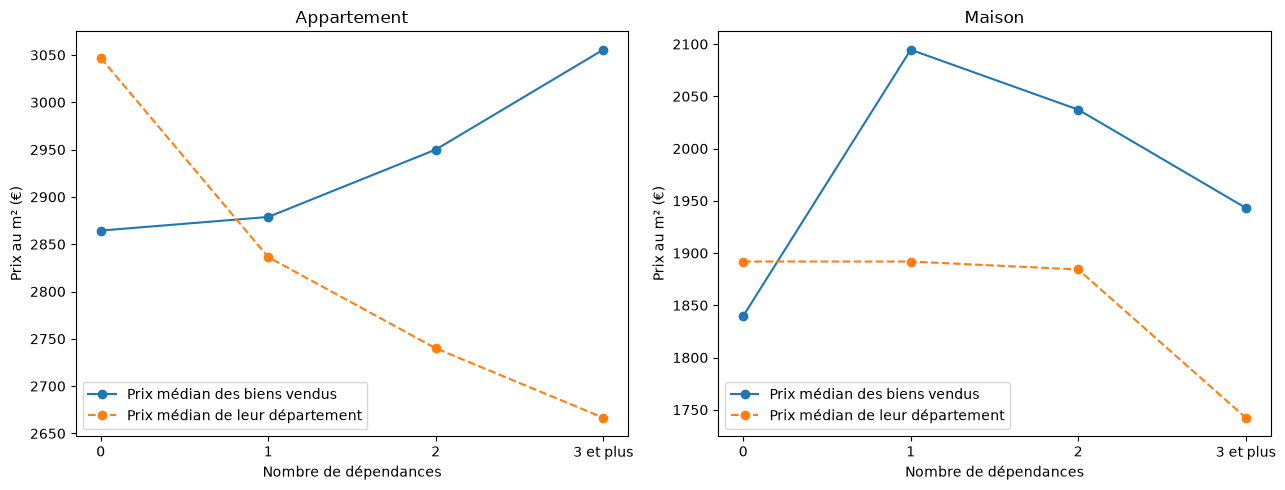

,type_bien,dep_classe,prix_bien,prix_departement
0,appartement,0,2864.0,3047.0
1,appartement,1,2879.0,2836.0
2,appartement,2,2950.0,2740.0
3,appartement,3 et plus,3056.0,2667.0
4,maison,0,1840.0,1892.0
5,maison,1,2095.0,1892.0
6,maison,2,2037.0,1884.0
7,maison,3 et plus,1943.0,1742.0


In [ ]:
# Prix médian du département de chaque vente (tableau dep calculé en B3)
prix_dep = dep[["coddep", "prix_m2_median"]].rename(columns={"prix_m2_median": "prix_dep"})
ech_dep = ech.merge(prix_dep, on="coddep", how="left")

# Pour chaque type et nombre de dépendances : prix des biens et prix de leur département
comp = (ech_dep.groupby(["type_bien", "dep_classe"], observed=True)
               .agg(prix_bien=("prix_m2", "median"), prix_departement=("prix_dep", "median"))
               .reset_index())
comp["dep_classe"] = comp["dep_classe"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, t in zip(axes, ["appartement", "maison"]):
    d = comp[comp["type_bien"] == t]
    ax.plot(d["dep_classe"], d["prix_bien"], marker="o", label="Prix médian des biens vendus")
    ax.plot(d["dep_classe"], d["prix_departement"], marker="o", linestyle="--",
            label="Prix médian de leur département")
    ax.set_title(t.capitalize())
    ax.set_xlabel("Nombre de dépendances")
    ax.set_ylabel("Prix au m² (€)")
    ax.legend()

plt.tight_layout()
plt.show()

comp.round(0)

**Résultat :**
- Appartements : ceux sans dépendance sont vendus dans les départements les plus chers (médiane du département : 3 047 €), mais leur prix est en dessous (2 864 €, environ -6 %). Ceux avec 3 dépendances et plus sont vendus dans des départements moins chers (2 667 €), mais leur prix est au-dessus (3 056 €, environ +15 %).
- Maisons : les départements sont presque les mêmes quel que soit le nombre de dépendances (environ 1 890 €). Les maisons avec au moins une dépendance se vendent plus cher que la médiane de leur département (2 095 € avec une dépendance, environ +11 %). Les maisons sans dépendance se vendent un peu en dessous (1 840 €).

**Interprétation :** les dépendances augmentent le prix au m² des appartements, mais cet effet était caché dans la première étape : les appartements sans dépendance se trouvent surtout dans les départements chers, ce qui faisait monter leur prix médian. Il faut donc regarder la localisation en même temps qu'une autre variable pour voir son vrai effet. Pour les maisons, avoir au moins une dépendance est associé à un prix plus élevé, mais en avoir plusieurs n'ajoute rien.

**Avis métier :** une cave ou un parking sont recherchés en ville et augmentent le prix d'un appartement. Dans les centres-villes très chers, beaucoup d'appartements se vendent sans parking. Pour une maison, le garage fait souvent partie du bâtiment et n'est pas compté comme dépendance.

**Impact projet :** le nombre de dépendances apporte une information sur le prix, surtout pour les appartements. Plus généralement, l'effet d'une variable peut être caché par la localisation : il faudra toujours en tenir compte dans le modèle.

**Action envisagée :** garder le nombre de dépendances comme variable, en tranches (0, 1, 2, 3 et plus).

**Biais / limites :** la localisation est mesurée au niveau du département, une maille large. Les axes du graphique ne commencent pas à 0 et n'ont pas la même échelle pour les maisons et les appartements : les écarts paraissent plus grands qu'ils ne sont. DVF+ ne précise pas le type de dépendance (cave, garage, parking).

In [ ]:
for t in ["appartement", "maison"]:
    d = ech[(ech["type_bien"] == t) & (ech["nb_pieces"] > 0)]
    rho, p = stats.spearmanr(d["sbati"], d["nb_pieces"])
    print(f"{t} : rho surface / nombre de pièces = {rho:.2f}")

appartement : rho surface / nombre de pièces = 0.87
maison : rho surface / nombre de pièces = 0.68


## Variables candidates pour la modélisation

| Variable / feature envisagée | Construite à partir de | Justification (fiche) |
|---|---|---|
| Prix médian au m² de l'année précédente | `prix_m2` | C4 : le prix d'une année dépend de la période |
| Nombre de ventes de l'année précédente | nombre de ventes | A2, C4 : fiabilité de la médiane, activité du marché |
| Part de maisons | `type_bien` | C2, C3 : deux marchés différents, effet de composition |
| Surface médiane | `sbati` | C1 : le prix au m² dépend de la surface |
| Part de studios, ou surface par pièce | `nbapt1pp` à `nbmai5pp`, `sbati` | C5 : effet propre du nombre de pièces |
| Part de ventes avec dépendance | `nblocdep` | C7 : effet des dépendances sur le prix des appartements |
| Part de maisons en copropriété | `sterr`, `nblot` | B6 : un terrain à 0 signale une copropriété |
| Département | `coddep` | C3 : la localisation est le facteur le plus fort |
| Année | `anneemut` | C4 : trois périodes différentes |
| Taux moyen des crédits immobiliers | Banque de France | C4 : à étudier dans la partie C |

## Prérequis à l'intégration

- **Clé et format :** code commune (5 caractères, en texte) et année. Code département en texte sur 2 caractères (2A et 2B pour la Corse). Si la cible est calculée par bassin de vie, il faudra ajouter le code du bassin de vie à chaque vente, à partir du code commune.
- **Maille :** commune × année pour l'instant. Une maille par bassin de vie × année est envisagée : elle regroupe plus de ventes, donc donne une médiane plus fiable dans les zones peu actives (A2).
- **Période / millésime :** 2014-2023 pour l'instant. Les codes commune devront être ramenés à un même millésime du Code officiel géographique. Le fichier des bassins de vie du projet est établi au 1er janvier 2024 : les codes commune de DVF+ devront être harmonisés sur ce millésime, sinon les communes fusionnées depuis 2014 ne trouveront pas leur bassin de vie.
- **Couverture (unités manquantes) :** pas de données pour l'Alsace-Moselle ni pour les DOM. Certaines communes n'ont aucune vente certaines années. Les communes sous le seuil de maille seront exclues ou regroupées, par exemple dans leur bassin de vie.

## À traiter au preprocessing (après intégration)

- Appliquer les règles d'exclusion de A1 (fonction `regles_exclusion`).
- Harmoniser les codes commune après les fusions de communes (table de passage de l'INSEE).
- Appliquer le seuil de maille ou le regroupement choisi par le groupe.
- Calculer les variables sur l'année précédente.
- Passer le prix au m² en log.
- Construire le nombre de pièces, la surface par pièce, la copropriété et les tranches de dépendances.
- Utiliser la surface en tranches, ou une transformation, puisque son lien avec le prix au m² n'est pas en ligne droite.
- Ajouter les variables territoriales issues des autres bases du projet, puisque la localisation est le facteur le plus fort.

## Hypothèses reportées au journal

- Les valeurs foncières absentes ont été codées 0 jusqu'en 2015, puis laissées vides : changement de codage non documenté.
- Les prix au m² très bas peuvent correspondre à des viagers ou à des ventes de parts, non repérables dans DVF+.
- À Paris, le studio et le 3 pièces ont le même prix au m², peut-être parce que les grands appartements y sont rares.
- La baisse des ventes en 2023 est probablement liée à la hausse des taux d'intérêt : à vérifier dans la partie C.

## Dette reportée (analyses non faites et pourquoi)

- **Liens avec les autres sources (taux d'intérêt, données territoriales) :** en attente des bases des autres membres du groupe.
- **Comparaison du neuf et de l'ancien :** demande de relire les fichiers bruts, puisque la VEFA a été retirée du périmètre. Son exclusion est justifiée dans l'audit.
- **Localisation plus fine que le département :** les coordonnées des parcelles (`geompar_x`, `geompar_y`) et le code commune le permettraient. Plusieurs analyses de C ont cette limite.
- **Effet de composition sur la cible commune × année :** vu à l'échelle nationale et départementale, pas encore mesuré commune par commune.
- **Années 2024 et 2025 :** volontairement non regardées, en attendant la décision sur la période et le découpage.

## Décisions ouvertes (à discuter en groupe)

- **Période définitive :** garder 2014-2023 en entier pour que le modèle voie plusieurs phases du marché (C4). Que faire de 2024 ?
- **Seuil de maille :** seuil de 10 ventes, seuil de 20 ventes, ou regroupement des petites communes/bassin de vie (A2).
- **Découpage entraînement / test :** aléatoire ou par date. Le cours sur les séries temporelles recommande un découpage par date pour éviter que le modèle voie l'avenir.
- **Cible unique ou séparée :** une cible pour tous les logements, ou une cible pour les maisons et une pour les appartements, à cause de l'effet de composition (C2, C3, C5).
- **Niveau du modèle :** prédire la cible commune × année, ou d'abord un prix par vente. Les analyses de B ont été faites vente par vente.